# Task 2: Exploratory Data Analysis (EDA) - Mall Customers Dataset

This notebook performs a comprehensive Exploratory Data Analysis (EDA) on the `Mall_Customers.csv` dataset. The analysis follows a structured process to understand customer behavior and segmentation:

1. **Ask Meaningful Questions**: Define hypotheses and exploration questions before looking at the data.
2. **Explore Data Structure**: Inspect columns, data types, dimensions, missing values, and summary statistics.
3. **Identify Trends, Patterns, and Anomalies**: Use visual and statistical summaries to discover relationships and outliers.
4. **Test Hypotheses and Validate Assumptions**: Formulate and run statistical tests to validate patterns.
5. **Detect Potential Data Issues**: Summarize observations, data issues, and recommendations for downstream analysis (e.g., clustering).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Set plotting styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

## 1. Ask Meaningful Questions About the Dataset

Before analyzing the data, we establish several key questions to guide our exploration:
* **Demographics**:
  * What is the age distribution of the mall customers?
  * What is the gender ratio among the customers?
* **Income & Spending**:
  * What is the average annual income of customers, and how is it distributed?
  * What is the average spending score, and how is it distributed?
* **Relationships**:
  * Is there a correlation between Age and Spending Score? (Do younger customers spend more?)
  * Do customers with higher annual incomes have higher spending scores?
  * Are there distinct customer segments/clusters visible in the Income vs. Spending space?
* **Gender-Based Differences**:
  * Do female customers have a higher average spending score than male customers?
  * Is there a significant difference in annual income between genders?

## 2. Explore the Data Structure

We start by loading the dataset and inspecting its columns, data types, shape, and statistical summaries.

In [ ]:
# Load the dataset
df = pd.read_csv('Mall_Customers.csv')

# View the first 5 rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# Check shape (dimensions)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")

# Check variables, data types, and missing values
df.info()

Dataset Dimensions: 200 rows, 5 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
# Get summary statistics
df.describe(include='all')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


## 3. Identify Trends, Patterns, and Anomalies

Let's visualize the data distributions, examine relationships between features, and look for outliers or anomalies.

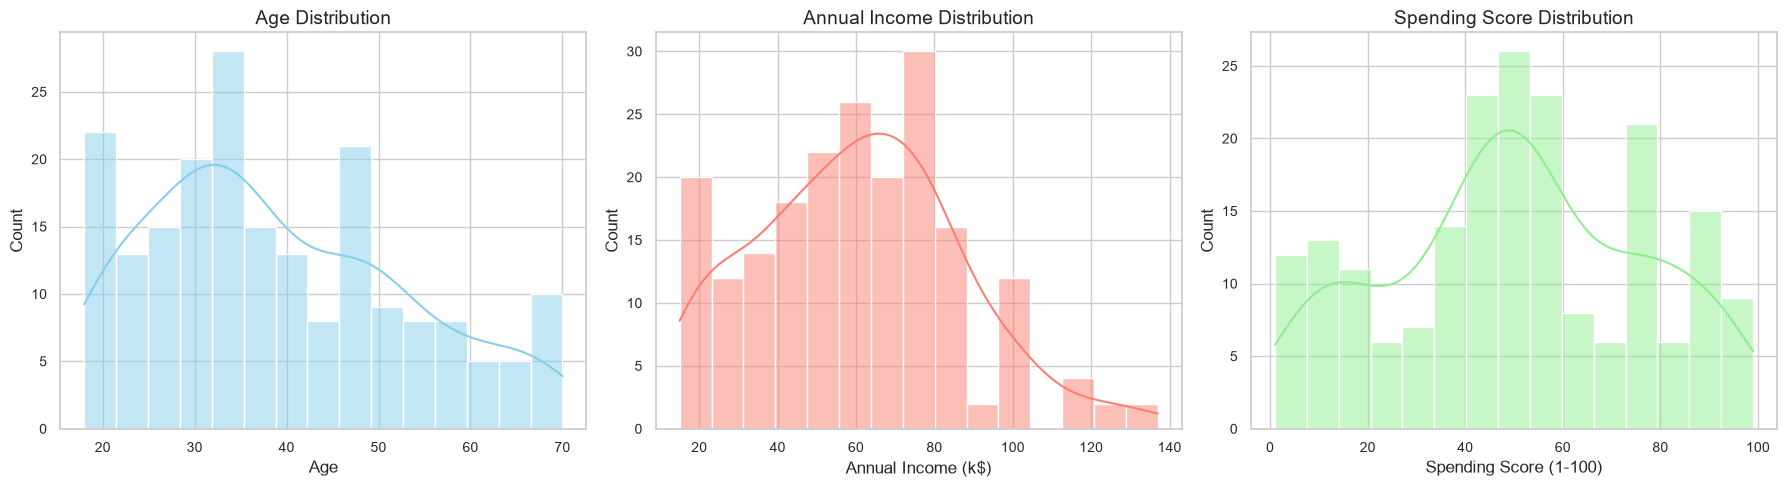

In [ ]:
# Set up subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot Age Distribution
sns.histplot(df['Age'], kde=True, ax=axes[0], color='skyblue', bins=15)
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')

# Plot Annual Income Distribution
sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[1], color='salmon', bins=15)
axes[1].set_title('Annual Income Distribution')
axes[1].set_xlabel('Annual Income (k$)')

# Plot Spending Score Distribution
sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[2], color='lightgreen', bins=15)
axes[2].set_title('Spending Score Distribution')
axes[2].set_xlabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

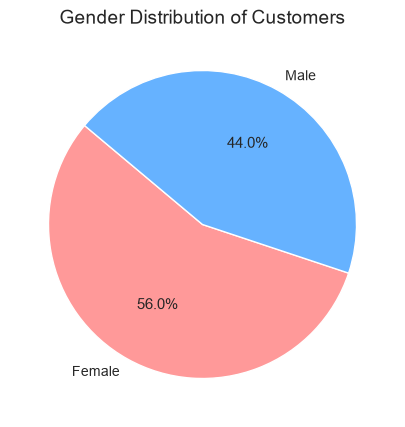

In [ ]:
# Gender Distribution
gender_counts = df['Gender'].value_counts()
plt.figure(figsize=(6, 5))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=['#FF9999', '#66B2FF'])
plt.title('Gender Distribution of Customers')
plt.show()

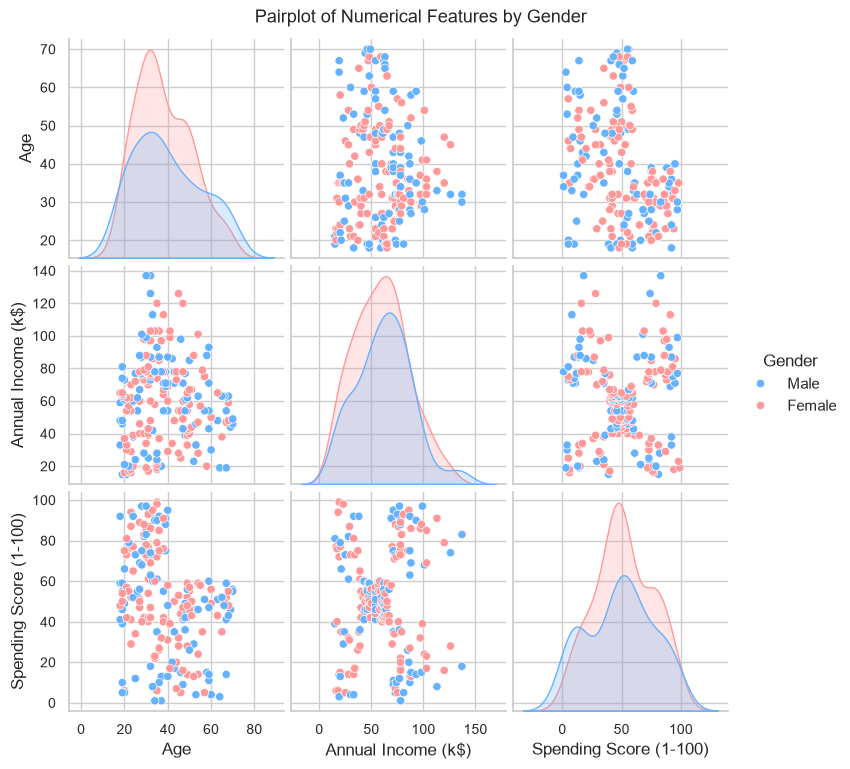

In [ ]:
# Explore relationships across all numerical variables segmented by Gender
sns.pairplot(df.drop(columns='CustomerID'), hue='Gender', palette=['#66B2FF', '#FF9999'], height=2.5)
plt.suptitle('Pairplot of Numerical Features by Gender', y=1.02)
plt.show()

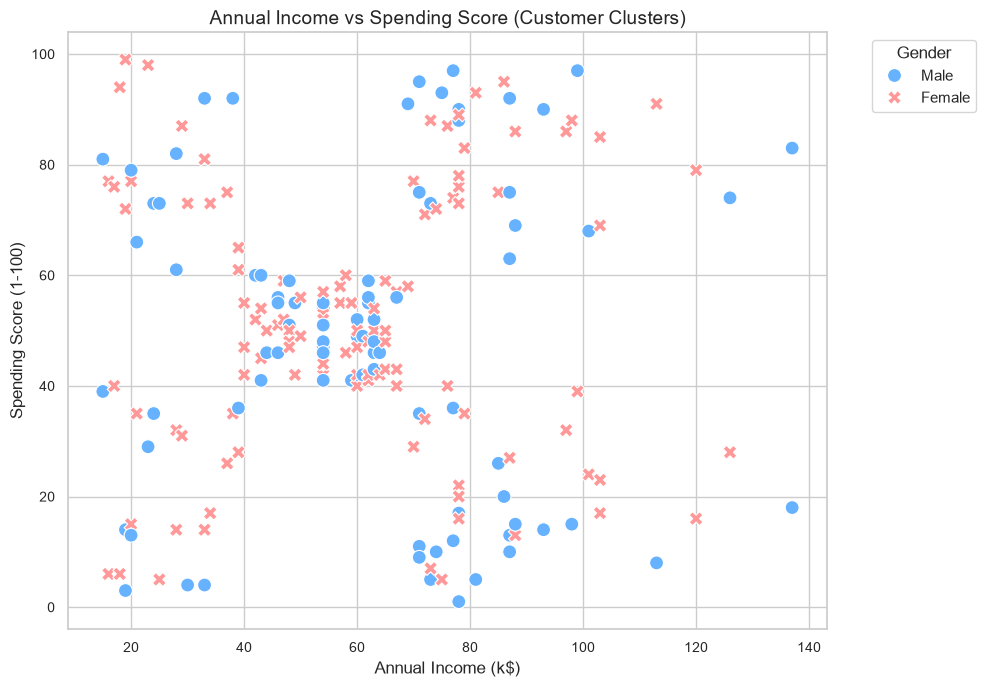

In [ ]:
# Annual Income vs Spending Score
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Gender', 
    style='Gender', 
    s=100, 
    palette=['#66B2FF', '#FF9999']
)
plt.title('Annual Income vs Spending Score (Customer Clusters)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Gender', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Observation**: The Income vs. Spending plot shows 5 highly distinct visual customer groups:
1. **Low Income, Low Spending Score**: Sensible / Budget shoppers.
2. **Low Income, High Spending Score**: Careless spenders.
3. **Average Income, Average Spending Score**: Standard middle-class consumers (dense cluster in the center).
4. **High Income, Low Spending Score**: High earners who are highly conservative with spending.
5. **High Income, High Spending Score**: High-value target clients (prime candidates for premium marketing).

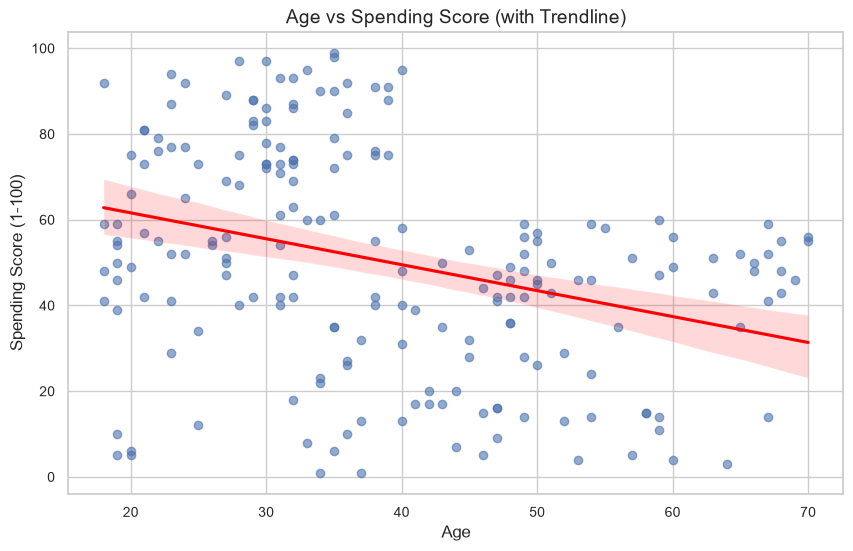

In [ ]:
# Age vs Spending Score
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Age', y='Spending Score (1-100)', scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
plt.title('Age vs Spending Score (with Trendline)')
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.show()

**Observation**: The negative trendline suggest that spending score generally decreases as age increases. Customers over the age of 40 rarely have a spending score above 60, whereas younger customers span the entire range, showing high spending scores (up to 100).

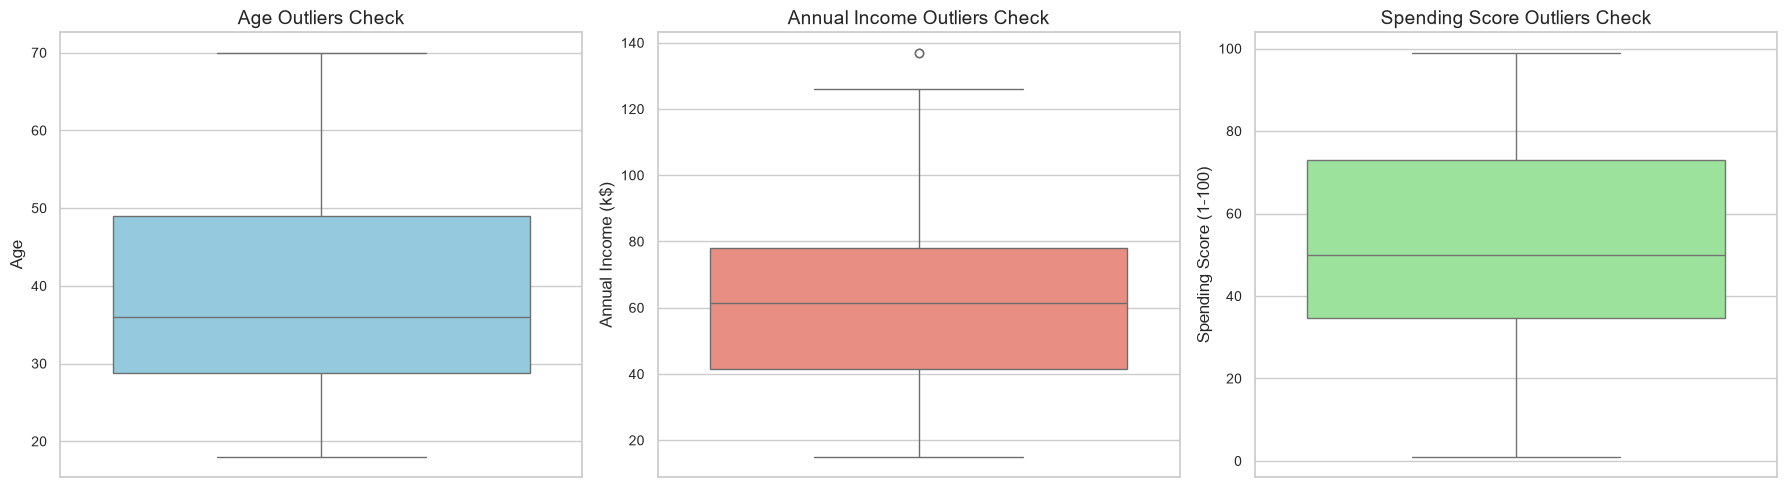

In [ ]:
# Boxplots to check for anomalies/outliers
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=df['Age'], ax=axes[0], color='skyblue')
axes[0].set_title('Age Outliers Check')

sns.boxplot(y=df['Annual Income (k$)'], ax=axes[1], color='salmon')
axes[1].set_title('Annual Income Outliers Check')

sns.boxplot(y=df['Spending Score (1-100)'], ax=axes[2], color='lightgreen')
axes[2].set_title('Spending Score Outliers Check')

plt.tight_layout()
plt.show()

In [ ]:
# Identify the specific outliers in Annual Income using Interquartile Range (IQR)
q1 = df['Annual Income (k$)'].quantile(0.25)
q3 = df['Annual Income (k$)'].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

outliers = df[(df['Annual Income (k$)'] > upper_bound) | (df['Annual Income (k$)'] < lower_bound)]
print(f"Upper Bound for Annual Income: {upper_bound} k$")
print(f"Number of outliers detected: {len(outliers)}")
outliers

Upper Bound for Annual Income: 132.75 k$
Number of outliers detected: 2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


## 4. Test Hypotheses and Validate Assumptions

We perform statistical testing to validate two main hypotheses:

### Hypothesis 1:
* **Null Hypothesis ($H_0$):** There is no significant difference in Spending Score between Male and Female customers.
* **Alternative Hypothesis ($H_1$):** There is a significant difference in Spending Score between Male and Female customers.
* **Method:** Two-sample independent t-test (at $lpha = 0.05$).

### Hypothesis 2:
* **Null Hypothesis ($H_0$):** There is no linear correlation between Age and Spending Score ($r = 0$).
* **Alternative Hypothesis ($H_1$):** There is a significant linear correlation between Age and Spending Score ($r \neq 0$).
* **Method:** Pearson's correlation coefficient test.

In [ ]:
# Group spending scores by gender
females = df[df['Gender'] == 'Female']['Spending Score (1-100)']
males = df[df['Gender'] == 'Male']['Spending Score (1-100)']

# Run T-test (Welch's t-test which does not assume equal variances)
t_stat, p_val = stats.ttest_ind(females, males, equal_var=False)

print("--- Hypothesis Test 1: Gender vs. Spending Score ---")
print(f"Female Average Spending Score: {females.mean():.2f}")
print(f"Male Average Spending Score: {males.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4f}")

alpha = 0.05
if p_val < alpha:
    print(f"P-value < {alpha}: Reject the Null Hypothesis (H0). There is a statistically significant difference in Spending Score between Male and Female customers.")
else:
    print(f"P-value >= {alpha}: Fail to reject the Null Hypothesis (H0). The observed difference in Spending Score between genders is not statistically significant.")

--- Hypothesis Test 1: Gender vs. Spending Score ---
Female Average Spending Score: 51.53
Male Average Spending Score: 48.51
T-statistic: 0.8049
P-value: 0.4220
P-value >= 0.05: Fail to reject the Null Hypothesis (H0). The observed difference in Spending Score between genders is not statistically significant.


In [ ]:
# Run Pearson's correlation test
corr, p_val_corr = stats.pearsonr(df['Age'], df['Spending Score (1-100)'])

print("--- Hypothesis Test 2: Age vs. Spending Score Correlation ---")
print(f"Pearson Correlation Coefficient (r): {corr:.4f}")
print(f"P-value: {p_val_corr:.4f}")

if p_val_corr < alpha:
    print(f"P-value < {alpha}: Reject the Null Hypothesis (H0). There is a statistically significant linear correlation between Age and Spending Score.")
else:
    print(f"P-value >= {alpha}: Fail to reject the Null Hypothesis (H0). The correlation is not statistically significant.")

--- Hypothesis Test 2: Age vs. Spending Score Correlation ---
Pearson Correlation Coefficient (r): -0.3272
P-value: 0.0000
P-value < 0.05: Reject the Null Hypothesis (H0). There is a statistically significant linear correlation between Age and Spending Score.


## 5. Potential Data Issues and Recommendations

### Identified Findings & Data Issues:
1. **Missing Data**: No missing values were found in any columns, indicating high data completeness.
2. **Outliers**: A minor anomaly exists in 'Annual Income' where two customers (IDs 199 and 200) have an income of 137 k$, which falls slightly above the statistical outlier limit of 132.75 k$. Since this is a realistic value, it does not represent corrupt data and should probably be kept, but scaling/normalization is recommended if applying distance-based models.
3. **Scale Variance**: Features have different ranges (Age: 18–70, Income: 15–137, Spending Score: 1–99). Distance-sensitive algorithms like K-Means clustering will require normalization (e.g., StandardScaler).
4. **Categorical Variable**: The `Gender` variable must be encoded (e.g., One-Hot or Label Encoding) before any machine learning modeling.

### Recommendations / Next Steps:
* **Target Clustering**: Given the clear visual grouping in the scatter plot, a K-Means clustering model with $k=5$ clusters would be highly appropriate for segmenting these customers.
* **Targeted Marketing**: 
  * Focus on the **High Income, High Spending** cluster with luxury/exclusive promotions.
  * Target the **Low Income, High Spending** cluster with impulse-buy campaigns or payment plans.
  * Address the **High Income, Low Spending** cluster with high-value/savings-oriented premium memberships.